# Ini

In [ ]:
import tensorflow as tf

# List all physical devices (GPUs)
physical_devices = tf.config.list_physical_devices('GPU')
print("Num GPUs Available: ", len(physical_devices))
print("Physical devices:", physical_devices)

# Get detailed information about the GPU
if physical_devices:
    for device in physical_devices:
        details = tf.config.experimental.get_device_details(device)
        print("Device Details:", details)
else:
    print("No GPU detected.")


In [2]:
import numpy as np
import random
import tensorflow as tf
from datetime import datetime
import h5py
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scikeras.wrappers import KerasRegressor
from bayes_opt import BayesianOptimization
from tensorflow.keras import layers, models, initializers
import time
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import statistics
from scipy import stats
from scipy.optimize import curve_fit
from tensorflow.keras.activations import tanh
import tensorflow.keras.backend as K
#import math

seed = 42  # L4 Labs, desk 19
np.random.seed(seed)
random.seed(seed)
tf.random.set_seed(seed)

print(f"Seed chosen: {seed} (last updated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')})")

Seed chosen: 42 (last updated: 2025-07-21 14:50:25)


# 1. Import Data

In [3]:
trainData_matFile = h5py.File('../data/26x26 TM Data/trainData_in.mat','r')
testData_matFile = h5py.File('../data/26x26 TM Data/testData_in.mat','r')
trainBendRadius_matFile = h5py.File('../data/26x26 TM Data/bend_radius_train.mat','r')
testBendRadius_matFile = h5py.File('../data/26x26 TM Data/bend_radius_test.mat','r')

x_train = trainData_matFile['trainData_in']
x_test = testData_matFile['testData_in']
y_train = trainBendRadius_matFile['bend_radius_train']
y_test = testBendRadius_matFile['bend_radius_test']

print("x train:", x_train.shape)
print("x test:", x_test.shape)
print("y train:", y_train.shape)
print("y test:", y_test.shape)

x train: (52, 52, 12000)
x test: (52, 52, 3000)
y train: (1, 12000)
y test: (1, 3000)


In [4]:
# take a subset of the 80,000 train, 20,000 test observations to test the programme
def small_subset(no_train_obs, no_test_obs): # number of training observations, number of validation/test observations

    x_train_small = x_train[:, :, 0:no_train_obs]
    x_test_small = x_test[:, :, 0:no_test_obs]
    y_train_small = y_train[:,0:no_train_obs]
    y_test_small = y_test[:,0:no_test_obs]
    print(" x train small shape:", x_train_small.shape, "\n",
          "x test small shape:", x_test_small.shape, "\n",
          "y train small shape:", y_train_small.shape, "\n",
          "y test small shape:", y_test_small.shape)
    return x_train_small, x_test_small, y_train_small, y_test_small, no_train_obs, no_test_obs

# reshape x_train_small and x_val_small if they are 3D, make them 4D

def reshape_small_subset(x_train_small, x_test_small, y_train_small, y_test_small, no_train_obs, no_test_obs):

    #x_train_small_expanded = np.expand_dims(x_train_small, axis=-1)  # adding a channel dimension to the end of the array. it's needed for the CNN
    #x_test_small_expanded = np.expand_dims(x_test_small, axis=-1)    # same as above

    # reshape X_train to (400, 156, 156, 1) for example (400 could be any number)
    x_train_small_reshaped = np.transpose(x_train_small, (2, 0, 1)).reshape(no_train_obs, 52, 52)
    x_test_small_reshaped = np.transpose(x_test_small, (2, 0, 1)).reshape(no_test_obs, 52, 52)

    # make sure y_train and y_test are properly shaped
    y_train_small_array = np.array(y_train_small)
    y_test_small_array = np.array(y_test_small)

    # reshape y_train to (400,)
    y_train_small_reshaped = y_train_small_array.flatten()

    # do the same for y_test
    y_test_small_reshaped = y_test_small_array.flatten()

    print("x train shape:", x_train_small_reshaped.shape)  # e.g. should be (400, 156, 156, 1)
    print("x test shape:", x_test_small_reshaped.shape)
    print("y train shape:", y_train_small_reshaped.shape)  # e.g. should be (400,)
    print("y test shape:", y_test_small_reshaped.shape)

    return x_train_small_reshaped, x_test_small_reshaped, y_train_small_reshaped, y_test_small_reshaped

no_train_obs = 12000
no_val_obs = 0
no_test_obs = 3000

small_subset_traintest = small_subset(no_train_obs + no_val_obs, no_test_obs)

x_train_small = small_subset_traintest[0]
x_test_small = small_subset_traintest[1]
y_train_small = small_subset_traintest[2]
y_test_small = small_subset_traintest[3]

reshape_small_subset_traintest = reshape_small_subset(x_train_small, x_test_small, y_train_small, y_test_small, 
                                                      no_train_obs + no_val_obs, no_test_obs)

x_train_all = reshape_small_subset_traintest[0]
x_test_all = reshape_small_subset_traintest[1]
y_train_all = reshape_small_subset_traintest[2]
y_test_all = reshape_small_subset_traintest[3]

print("\nSeed Value:", seed)

 x train small shape: (52, 52, 12000) 
 x test small shape: (52, 52, 3000) 
 y train small shape: (1, 12000) 
 y test small shape: (1, 3000)
x train shape: (12000, 52, 52)
x test shape: (3000, 52, 52)
y train shape: (12000,)
y test shape: (3000,)

Seed Value: 42


In [5]:
x_train_split, x_val_split, y_train_split, y_val_split = train_test_split(x_train_all, y_train_all, test_size=0.125, random_state=seed)

print("Training Set TM Shape:", x_train_split.shape)
print("Validation Set TM Shape:", x_val_split.shape)
print("Test Set TM Shape:", x_test_all.shape)
print("Training Set Radius Shape:", y_train_split.shape)
print("Validation Set Radius Shape:", y_val_split.shape)
print("Test Set Radius Shape:", y_test_all.shape)

Training Set TM Shape: (10500, 52, 52)
Validation Set TM Shape: (1500, 52, 52)
Test Set TM Shape: (3000, 52, 52)
Training Set Radius Shape: (10500,)
Validation Set Radius Shape: (1500,)
Test Set Radius Shape: (3000,)


In [6]:
def calculate_cond_nums(dataset):
    cond_nums_list = []
    failed_indices = []  # To store indices of matrices where SVD fails

    for tm in range(0, len(dataset), 1):
        try:
            # Attempt to calculate the condition number
            cond_num = np.linalg.cond(dataset[tm])
            if cond_num < 10000:
                cond_nums_list.append(cond_num)
            else:
                failed_indices.append(tm)
        except np.linalg.LinAlgError:
            # If SVD fails, store the index and skip this matrix
            failed_indices.append(tm)

    return cond_nums_list, failed_indices

# Example usage
train_cond_nums, failed_train_indices = calculate_cond_nums(x_train_split)
val_cond_nums, failed_val_indices = calculate_cond_nums(x_val_split)
test_cond_nums, failed_test_indices = calculate_cond_nums(x_test_all)

# Combine condition numbers from all datasets
all_cond_nums = train_cond_nums + val_cond_nums + test_cond_nums

# Print the min and max condition numbers
print(f'Minimum cond num: {min(all_cond_nums):.5f}, maximum cond num: {max(all_cond_nums):.5f}')

# Print indices of matrices where SVD failed
print(f"Failed indices in train set: {failed_train_indices}")
print(f"Failed indices in validation set: {failed_val_indices}")
print(f"Failed indices in test set: {failed_test_indices}")


Minimum cond num: 1.00000, maximum cond num: 1.00000
Failed indices in train set: []
Failed indices in validation set: []
Failed indices in test set: []


In [7]:
def find_y_0(y_data):
    zero_indices = []

    for value in range(0, len(y_data), 1):
        if (y_data[value] < 0.05) and (y_data[value] > -0.05):
            zero_indices.append(value)

    return zero_indices

y_train_zeros = find_y_0(y_train_split)
y_val_zeros = find_y_0(y_val_split)
y_test_zeros = find_y_0(y_test_all)

y_test_zeros

[]

In [8]:
train_indices_to_remove = failed_train_indices + y_train_zeros
val_indices_to_remove = failed_val_indices + y_val_zeros
test_indices_to_remove = failed_test_indices + y_test_zeros

In [9]:
x_train_f = np.delete(x_train_split, train_indices_to_remove, axis=0)
y_train_f = np.delete(y_train_split, train_indices_to_remove, axis=0)
x_val_f = np.delete(x_val_split, val_indices_to_remove, axis=0)
y_val_f = np.delete(y_val_split, val_indices_to_remove, axis=0)
x_test_f = np.delete(x_test_all, test_indices_to_remove, axis=0)
y_test_f = np.delete(y_test_all, test_indices_to_remove, axis=0)

print("Training Set TM Shape:", x_train_f.shape)
print("Validation Set TM Shape:", x_val_f.shape)
print("Test Set TM Shape:", x_test_f.shape)
print("Training Set Radius Shape:", y_train_f.shape)
print("Validation Set Radius Shape:", y_val_f.shape)
print("Test Set Radius Shape:", y_test_f.shape)

Training Set TM Shape: (10500, 52, 52)
Validation Set TM Shape: (1500, 52, 52)
Test Set TM Shape: (3000, 52, 52)
Training Set Radius Shape: (10500,)
Validation Set Radius Shape: (1500,)
Test Set Radius Shape: (3000,)


# 2. Data Analysis

(array([336., 338., 326., 353., 311., 323., 327., 338., 333., 348., 333.,
        332., 308., 290., 313., 325.,   0., 357., 346., 326., 323., 329.,
        317., 323., 327., 325., 332., 331., 332., 308., 345., 331., 313.]),
 array([-0.85, -0.8 , -0.75, -0.7 , -0.65, -0.6 , -0.55, -0.5 , -0.45,
        -0.4 , -0.35, -0.3 , -0.25, -0.2 , -0.15, -0.1 , -0.05,  0.05,
         0.1 ,  0.15,  0.2 ,  0.25,  0.3 ,  0.35,  0.4 ,  0.45,  0.5 ,
         0.55,  0.6 ,  0.65,  0.7 ,  0.75,  0.8 ,  0.85]),
 <BarContainer object of 33 artists>)

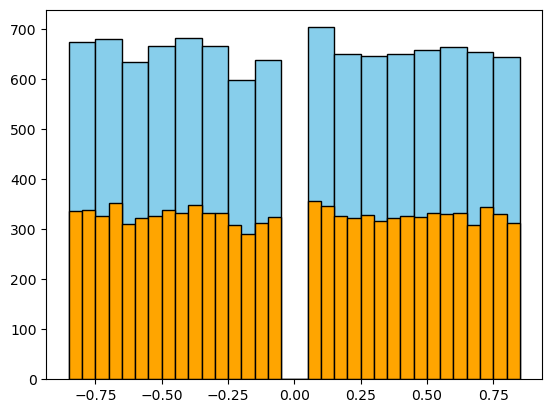

In [10]:

plt.hist(y_train_f, bins=[-0.85, -0.75, -0.65, -0.55, -0.45, -0.35, -0.25, -0.15, -0.05, 0.05, 0.15, 0.25, 0.35, 0.45, 0.55, 0.65, 0.75, 0.85], color='skyblue', edgecolor='black')
plt.hist(y_train_f, bins=[-0.85, -0.8, -0.75, -0.7, -0.65, -0.6, -0.55, -0.5, -0.45, -0.4, -0.35, -0.3, -0.25, -0.2, -0.15, -0.1, -0.05, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85], color='orange', edgecolor='black')


Matrix 1 index 0, size: (52, 52)
Matrix 2 index 10000, size: (52, 52)


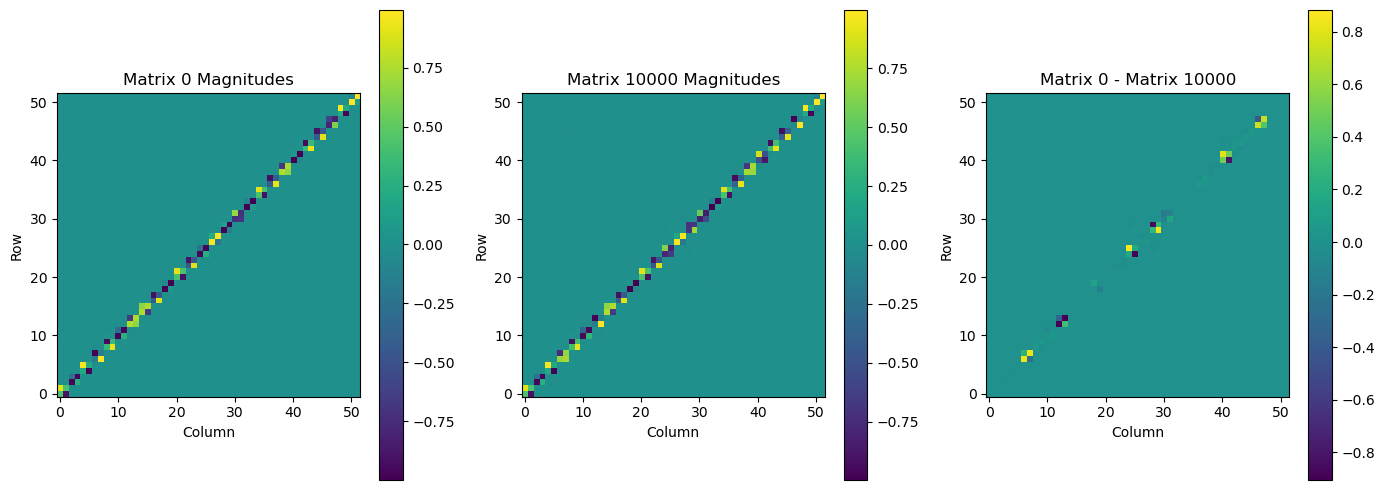

In [11]:
# Example matrix
matrices_chosen = 0, 10000

matrix1 = x_train_f[matrices_chosen[0]]
matrix1 = np.squeeze(matrix1)  # Remove the last dimension (156, 156, 1 -> 156, 156)
print(f'Matrix 1 index {matrices_chosen[0]}, size: {matrix1.shape}')
#matrix1_mags = np.abs(matrix1) # Choose the property to visualize (e.g., magnitude)

matrix2 = x_train_f[matrices_chosen[1]]
matrix2 = np.squeeze(matrix2)  # Remove the last dimension (156, 156, 1 -> 156, 156)
print(f'Matrix 2 index {matrices_chosen[1]}, size: {matrix2.shape}')
#matrix2_mags = np.abs(matrix2) # Choose the property to visualize (e.g., magnitude)

plt.figure(figsize=(14, 5))  # Adjust figure size to fit both plots

# Plot the first heatmap
plt.subplot(1, 3, 1)  # 1 row, 3 columns, first subplot
plt.imshow(matrix1, cmap='viridis', origin='lower')
plt.colorbar()
plt.title(f'Matrix {matrices_chosen[0]} Magnitudes')
plt.xlabel('Column')
plt.ylabel('Row')

plt.subplot(1, 3, 2)  # 1 row, 3 columns, second subplot
plt.imshow(matrix2, cmap='viridis', origin='lower')
plt.colorbar()
plt.title(f'Matrix {matrices_chosen[1]} Magnitudes')
plt.xlabel('Column')
plt.ylabel('Row')

plt.subplot(1, 3, 3)  # 1 row, 3 columns, third subplot
plt.imshow(matrix2 - matrix1, cmap='viridis', origin='lower')
plt.colorbar()
plt.title(f'Matrix {matrices_chosen[0]} - Matrix {matrices_chosen[1]}')
plt.xlabel('Column')
plt.ylabel('Row')

# Show both plots side by side
plt.tight_layout()
plt.show()


In [12]:
def to_complex(matrix):
    """
    Converts a real number matrix into complex numbers equivalents.
    The top-left of each 2x2 block is the real part,
    the top-right is the imaginary part.
    """
    real_part = matrix[:, ::2][::2]  # Take every other row & column (top-left values)
    imag_part = matrix[:, 1::2][::2]  # Take every other row, starting from column 1 (top-right values)

    return real_part + 1j * imag_part  # Convert to complex numbers

In [13]:
def find_min_max(dataset):
    mins = []
    maxs = []

    for tm in range(0, len(dataset), 1):
        tmm = to_complex(dataset[tm])
        minn = tmm.min()
        maxn = tmm.max()
        mins.append(minn)
        maxs.append(maxn)

    return mins, maxs

train_mins, train_maxs = find_min_max(x_train_f)
val_mins, val_maxs = find_min_max(x_val_f)
test_mins, test_maxs = find_min_max(x_test_f)

print(min(train_mins), max(train_maxs))
print(min(val_mins), max(val_maxs))
print(min(test_mins), min(test_maxs))

(-0.9999992-0.00023324287j) (0.999994-1.6034926e-05j)
(-0.9999992-0.0001417243j) (0.99992615-0.011840256j)
(-0.9999992-5.01767e-05j) (0.9940444+0.108975336j)


In [14]:
amplitudes = np.abs(x_train_f[123])
np.sum(amplitudes)

66.065765

# 3. Hyperparameter Tuning Simple Weighted MAE

In [22]:
# single head with residual connections
class SingleHeadSelfAttentionResidual_tune(layers.Layer):
    def __init__(self, embed_dim):
        super(SingleHeadSelfAttentionResidual_tune, self).__init__()
        self.embed_dim = embed_dim

        # define dense layers for query, key, value transformations
        self.query_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())
        self.key_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                      bias_initializer=initializers.Zeros())
        self.value_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())
        self.output_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                         bias_initializer=initializers.Zeros())

        # normalization for stabilization. attention -> add residual connections -> normalisation is standard in transformers
        self.layer_norm = layers.LayerNormalization(epsilon=1e-6, beta_initializer='zeros', gamma_initializer='ones')

    def call(self, inputs):
        # inputs shape: (batch_size, num_patches, patch_height, embed_dim), (batch_size, 78, 2, 16)

        # compute queries, keys, and values
        queries = self.query_dense(inputs)  # shape: (None, 78, 2, 16)
        keys = self.key_dense(inputs)       # shape: (None, 78, 2, 16)
        values = self.value_dense(inputs)   # shape: (None, 78, 2, 16)

        # compute attention scores
        score = tf.matmul(queries, keys, transpose_b=True)  # shape: (batch_size, 78, 78)
        dim_k = tf.cast(tf.shape(keys)[-1], tf.float32) # cast the last dimension of keys (it's size) to a 32 bit floating-point number
        scaled_score = score / tf.math.sqrt(dim_k)  # scaling adds stability
        attention_weights = tf.nn.softmax(scaled_score, axis=-1)  # shape: (batch_size, 78, 78)

        # compute context vector as weighted sum of values
        context_vector = tf.matmul(attention_weights, values)  # shape: (batch_size, 78, 2, 16)

        # add residual connection (input + context vector)
        output_with_residual = layers.Add()([inputs, context_vector])

        # layer Normalization, mainly to ensure stability
        normalized_output = self.layer_norm(output_with_residual)

        # passing through dense layer to refine output, however i'm not sure how relevant this is
        return self.output_dense(normalized_output), attention_weights

def weighted_mae(y_true, y_pred):
    weight = tf.where(y_true > 0, 1.0 / (K.abs(y_true) + 0.004), 1.0 / (K.abs(y_true) + 0.01)) #1.0 / (K.abs(y_true) + 0.01)
    return K.mean(weight * K.abs(y_true - y_pred))

def relative_mae(y_true, y_pred):
    return K.mean(K.abs(y_true - y_pred) / (K.abs(y_true)))

def SingleHeadResidualModel_tune(activation_func, dense_neur = 42, learning_rate = 0.001):
    inputs = layers.Input(shape=(52, 52, 1))

    patch_height, patch_width = 2, 78 # patch size: 2 rows and 52 columns
    num_patches = 52 // patch_height

    dense_neur = int(dense_neur)
    x = layers.Reshape((num_patches, patch_height, patch_width))(inputs)

    # z=x⋅W+b (x = input, W = learned weights (shape 156, 16), b = bias (vector of shape 16,), params = 2512 = 156 * 16 + 16
    # afterwards the output (z) is passed to the non-linear activation, where z = z if z >= 0, and z = a*z if z < 0. a is the slope for negative values, typically a small constant like 0.01.
    if activation_func > 0.5:
        x = layers.Dense(dense_neur, activation = tanh, kernel_initializer=initializers.GlorotUniform(seed=seed), # kernel initialiser = weights initialiser
                                        bias_initializer=initializers.Zeros())(x) # reduce feature dimension from 156 to 16 for each patch
    else:
        x = layers.Dense(dense_neur, activation = None, kernel_initializer=initializers.GlorotUniform(seed=seed), # kernel initialiser = weights initialiser
                                        bias_initializer=initializers.Zeros())(x) # reduce feature dimension from 156 to 16 for each patch

    x = layers.LayerNormalization(epsilon=1e-6)(x)

    x, _ = SingleHeadSelfAttentionResidual_tune(embed_dim = dense_neur)(x) # self-attention layer

    # reshape to 3D for global average pooling: (batch_size, num_patches, patch_height * embed_dim)
    # global average pooling 1D only accepts 3d tensors.
    x_reshaped = layers.Reshape((num_patches, patch_height * dense_neur))(x)

    # originally had a flattening layer but replaced with global average pooling to help the model generalize better and reduce overfitting
    # pooling used to reduce spatial dimensions, in turn preventing overfitting.
    x_before_dense = layers.GlobalAveragePooling1D()(x_reshaped) # apply Global Average Pooling along the patches dimension only

    x = layers.LayerNormalization(epsilon=1e-6)(x_before_dense)

    # maybe i should've added an activation function (i.e. leaky_relu)
    output = layers.Dense(1, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())(x)

    # compile the model
    model = models.Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss = weighted_mae, metrics=['mae'])

    return model


In [24]:
from sklearn.metrics import mean_squared_error
t1 = time.perf_counter()

def CVBayes_SingleHeadFull(learning_rate, batch_size, epochs, dense_neur, activation_func):
    batch_size = int(round(batch_size))  # Ensure batch_size is an integer
    epochs = int(round(epochs))  # Ensure epochs is an integer

    model = KerasRegressor(
        model=SingleHeadResidualModel_tune,
        learning_rate=learning_rate,
        epochs=epochs,
        batch_size=batch_size,
        dense_neur = dense_neur,
        activation_func = activation_func,
        verbose=0)

    early_stopping = EarlyStopping(monitor='val_mae', mode = 'min', patience = 35, restore_best_weights = True, verbose = 1)

    model.fit(x_train_f, y_train_f, validation_data=(x_val_f, y_val_f), callbacks = [early_stopping])

    y_pred = model.predict(x_val_f)

    weighted_mae_tune = weighted_mae(y_val_f, y_pred)

    # Return the mean score
    return -weighted_mae_tune

pbounds = {
    'learning_rate': (0.0001, 0.01),  # Continuous range for learning rate
    'batch_size': (24, 48),  # this may need reducing to reduce memory load
    'epochs': (15, 60), # increased as a smaller learning rate but higher epochs seems to work well (especially with residual connection models)
    'dense_neur': (16, 46),
    'activation_func': [0, 1]
}

# Bayesian tries to balance between exploration (trying new areas) and exploitation (refining known good areas)
optimizer = BayesianOptimization(f=CVBayes_SingleHeadFull, pbounds=pbounds, random_state=seed)

# init_points: number of random points to probe before starting the optimization. it uses these points to create a Gaussian model to sample from
# n_iter: defines the number of iterations the optimization process should perform after the initial random sampling
optimizer.maximize(init_points=12, n_iter=25) # the total number of iterations will be init_points + n_iter

print("Best parameters found: ", optimizer.max['params'])
print("Best score: ", optimizer.max['target'])

t2 = time.perf_counter()
print('\nTime taken to run:', round(t2-t1, 1), 'seconds')


|   iter    |  target   | activa... | batch_... | dense_... |  epochs   | learni... |
-------------------------------------------------------------------------------------
| 1         | -0.0458   | 0.3745    | 46.82     | 37.96     | 41.94     | 0.001645  |
| 2         | -0.05689  | 0.156     | 25.39     | 41.99     | 42.05     | 0.00711   |
| 3         | -0.101    | 0.02058   | 47.28     | 40.97     | 24.56     | 0.0019    |
| 4         | -0.02953  | 0.1834    | 31.3      | 31.74     | 34.44     | 0.002983  |
| 5         | -0.02813  | 0.6119    | 27.35     | 24.76     | 31.49     | 0.004615  |
| 6         | -0.09915  | 0.7852    | 28.79     | 31.43     | 41.66     | 0.0005599 |
| 7         | -0.02741  | 0.6075    | 28.09     | 17.95     | 57.7      | 0.00966   |
| 8         | -0.01291  | 0.8084    | 31.31     | 18.93     | 45.79     | 0.004458  |
| 9         | -0.03167  | 0.122     | 35.88     | 17.03     | 55.92     | 0.002662  |
| 10        | -0.04324  | 0.6625    | 31.48     | 31.6

# 4. Train Final Model [Standard Weighted MAE Loss Function]

## 4a. Functions

In [10]:
# single head with residual connections
class SingleHeadSelfAttentionResidual(layers.Layer):
    def __init__(self, embed_dim):
        super(SingleHeadSelfAttentionResidual, self).__init__()
        self.embed_dim = embed_dim

        # define dense layers for query, key, value transformations
        self.query_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())
        self.key_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                      bias_initializer=initializers.Zeros())
        self.value_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())
        self.output_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                         bias_initializer=initializers.Zeros())

        # normalization for stabilization. attention -> add residual connections -> normalisation is standard in transformers
        self.layer_norm = layers.LayerNormalization(epsilon=1e-6, beta_initializer='zeros', gamma_initializer='ones')

    def call(self, inputs):
        # inputs shape: (batch_size, num_patches, patch_height, embed_dim), (batch_size, 78, 2, 16)

        # compute queries, keys, and values
        queries = self.query_dense(inputs)  # shape: (None, 78, 2, 16)
        keys = self.key_dense(inputs)       # shape: (None, 78, 2, 16)
        values = self.value_dense(inputs)   # shape: (None, 78, 2, 16)

        # compute attention scores
        score = tf.matmul(queries, keys, transpose_b=True)  # shape: (batch_size, 78, 78)
        dim_k = tf.cast(tf.shape(keys)[-1], tf.float32) # cast the last dimension of keys (it's size) to a 32 bit floating-point number
        scaled_score = score / tf.math.sqrt(dim_k)  # scaling adds stability
        attention_weights = tf.nn.softmax(scaled_score, axis=-1)  # shape: (batch_size, 78, 78)

        # compute context vector as weighted sum of values
        context_vector = tf.matmul(attention_weights, values)  # shape: (batch_size, 78, 2, 16)

        # add residual connection (input + context vector)
        output_with_residual = layers.Add()([inputs, context_vector])

        # layer Normalization, mainly to ensure stability
        normalized_output = self.layer_norm(output_with_residual)

        # passing through dense layer to refine output, however i'm not sure how relevant this is
        return self.output_dense(normalized_output), attention_weights

In [11]:
#def weighted_mae(y_true, y_pred):
#    weight = tf.where(y_true > 0, 1.0 / (K.abs(y_true) + 0.004), 1.0 / (K.abs(y_true) + 0.01)) #1.0 / (K.abs(y_true) + 0.01)
#    return K.mean(weight * K.abs(y_true - y_pred)/K.abs(y_true))

def weighted_mae(y_true, y_pred):
    x_pos = 0.004
    x_neg = 0.01
    abs_error = K.abs(y_true - y_pred)

    # Compute weights
    weight = tf.where(y_true > 0, 1.0 / (K.abs(y_true) + x_pos), 1.0 / (K.abs(y_true) + x_neg))

    # Compute separate MAEs
    mae_pos = K.sum(weight * abs_error * tf.cast(y_true > 0, tf.float32)) / (K.sum(tf.cast(y_true > 0, tf.float32)) + K.epsilon())
    mae_neg = K.sum(weight * abs_error * tf.cast(y_true < 0, tf.float32)) / (K.sum(tf.cast(y_true < 0, tf.float32)) + K.epsilon())

    # Balance penalty (forces equal optimization)
    balance_penalty = 1.0 + K.abs(mae_pos - mae_neg)

    return K.mean(weight * K.abs(y_true - y_pred)/K.abs(y_true)) * balance_penalty

In [17]:
def SingleHeadResidualModel(dense_neurons = int(22.212316006880545), learning_rate = round(0.005565249919690282, 6)):
    inputs = layers.Input(shape=(52, 52, 1))  # input shape: (batch_size, 156, 156, 1)

    patch_height, patch_width = 2, 52 # patch size: 2 rows and 156 columns
    num_patches = 52 // patch_height  # number of patches along the height dimension (i.e. 78)

    x = layers.Reshape((num_patches, patch_height, patch_width))(inputs)  # reshape input into 78 patches of size (2, 156)

    # z=x⋅W+b (x = input, W = learned weights (shape 156, 16), b = bias (vector of shape 16,), params = 2512 = 156 * 16 + 16
    # afterwards the output (z) is passed to the non-linear activation, where z = z if z >= 0, and z = a*z if z < 0. a is the slope for negative values, typically a small constant like 0.01.
    x = layers.Dense(dense_neurons, activation= tanh, kernel_initializer=initializers.GlorotUniform(seed=seed), # kernel initialiser = weights initialiser
                                            bias_initializer=initializers.Zeros())(x) # reduce feature dimension from 156 to 16 for each patch

    x = layers.LayerNormalization(epsilon=1e-6)(x) # provides stability and improves generalisation, it normalises the outputs of the previous layer using: (input - mean) / sqrt(var)

    x, _ = SingleHeadSelfAttentionResidual(embed_dim = dense_neurons)(x) # self-attention layer

    # reshape to 3D for global average pooling: (batch_size, num_patches, patch_height * embed_dim)
    # global average pooling 1D only accepts 3d tensors.
    x_reshaped = layers.Reshape((num_patches, patch_height * dense_neurons))(x)

    # originally had a flattening layer but replaced with global average pooling to help the model generalize better and reduce overfitting
    # pooling used to reduce spatial dimensions, in turn preventing overfitting.
    x_before_dense = layers.GlobalAveragePooling1D()(x_reshaped) # apply Global Average Pooling along the patches dimension only

    x = layers.LayerNormalization(epsilon=1e-6)(x_before_dense)

    # maybe i should've added an activation function (i.e. leaky_relu)
    output = layers.Dense(1, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())(x)

    # compile the model
    model = models.Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss=weighted_mae, metrics=['mae'])

    return model

In [13]:
def to_complex(matrix):
    """
    Converts a real number matrix into complex numbers equivalents.
    The top-left of each 2x2 block is the real part,
    the top-right is the imaginary part.
    """
    real_part = matrix[:, ::2][::2]  # Take every other row & column (top-left values)
    imag_part = matrix[:, 1::2][::2]  # Take every other row, starting from column 1 (top-right values)

    return real_part + 1j * imag_part  # Convert to complex numbers


In [14]:
def compare_real_and_pred_tms(real_tm, predicted_tm, real_radius, predicted_radius, data_part):
    matrix1 = np.squeeze(real_tm)  # Ensure correct shape
    matrix2 = np.squeeze(predicted_tm)

    print(f'Real TM ({real_radius}m), size: {matrix1.shape}')
    print(f'Predicted TM ({predicted_radius}m), size: {matrix2.shape}')

    # Compute phase alignment
    phaseError_TM = np.angle(np.trace(matrix2 @ matrix1.conj().T))
    matrix2_aligned = matrix2 * np.exp(-1j * phaseError_TM)

    plt.figure(figsize=(14, 5))

    # Real or Phase TM visualization
    plt.subplot(1, 3, 1)
    if data_part == 'real':
        plt.imshow(abs(matrix1), cmap='viridis', origin='lower')
        plt.title(f'Real TM ({real_radius}m) [Amplitude]')
    elif data_part == 'imag':
        plt.imshow(np.angle(matrix1), cmap='twilight', origin='lower')
        plt.title(f'Real TM ({real_radius}m) [Phase]')
    plt.colorbar()

    plt.subplot(1, 3, 2)
    if data_part == 'real':
        plt.imshow(abs(matrix2_aligned), cmap='viridis', origin='lower')
        plt.title(f'Predicted TM ({predicted_radius}m) [Amplitude]')
    elif data_part == 'imag':
        plt.imshow(np.angle(matrix2_aligned), cmap='twilight', origin='lower')
        plt.title(f'Predicted TM ({predicted_radius}m) [Phase]')
    plt.colorbar()

    plt.subplot(1, 3, 3)
    if data_part == 'real':
        plt.imshow(abs(matrix2_aligned - matrix1), cmap='viridis', origin='lower')
        plt.title(f'Real TM - Predicted TM [Amplitude]')
    elif data_part == 'imag':
        plt.imshow(np.angle(matrix2_aligned) - np.angle(matrix1), cmap='twilight', origin='lower')
        plt.title(f'Phase Difference (Real - Predicted)')
    plt.colorbar()

    # Compute official error metric
    error_TM = np.linalg.norm(matrix2 - matrix1 * np.exp(-1j * phaseError_TM)) / np.linalg.norm(matrix1) * 100
    print(f'Error TM: {error_TM:.5f}%')

    plt.tight_layout()
    plt.show()


## 4b. Training

In [ ]:
#optimal_batch_size_bayesian = int(round(list(optimizer.max['params'].values())[0], 0))
#optimal_epochs_bayesian = int(round(list(optimizer.max['params'].values())[1], 0))
#optimal_learning_rate_bayesian = round(list(optimizer.max['params'].values())[2], 5)

#optimal_batch_size_bayesian = int(round(31.310730460160897, 0))
#optimal_dense_neurons_bayesian = int(24)#17.95344228012768)
#optimal_epochs_bayesian = int(round(45.79048619304706 + 15, 0))
#optimal_learning_rate_bayesian = round(0.0044575096880220535, 6)

optimal_batch_size_bayesian = int(round(27.883189469819506, 0))
optimal_dense_neurons_bayesian = int(22.212316006880545)
optimal_epochs_bayesian = int(round(56.345735791242774 +34, 0))
optimal_learning_rate_bayesian = round(0.005565249919690282, 6)

print("Batch Size Used:", optimal_batch_size_bayesian)
print("Epochs Used:", optimal_epochs_bayesian)
print("Learning Rate Used:", optimal_learning_rate_bayesian, "\n")

t1 = time.perf_counter()

# instantiate the model
SingleHeadResidualModel_Final = SingleHeadResidualModel(optimal_dense_neurons_bayesian, optimal_learning_rate_bayesian)

# shows summary of the model
SingleHeadResidualModel_Final.summary()

early_stopping = EarlyStopping(monitor='val_mae', mode = 'min', patience = 15, restore_best_weights = True, verbose = 1)

# training
history = SingleHeadResidualModel_Final.fit(x_train_f, y_train_f, epochs = optimal_epochs_bayesian, batch_size = optimal_batch_size_bayesian, verbose = 1,
                                           validation_data = (x_val_f, y_val_f), callbacks = [early_stopping])

# evaluate the model using the validation set
test_loss, test_mae = SingleHeadResidualModel_Final.evaluate(x_test_f, y_test_f)

y_pred = SingleHeadResidualModel_Final.predict(x_test_f)

print(f"Test Set MAE: {test_mae:.4f}")
print("Out of sample error:", round((test_mae/statistics.mean(abs(y_test_f)))*100, 2), "%")

t2 = time.perf_counter()
print('\nTime taken to run:', round(t2-t1, 1), 'seconds')


In [ ]:
#SingleHeadResidualModel_Final.save_weights('../models/67%Model.weights.h5')

0.06742294132709503 0.06786361336708069


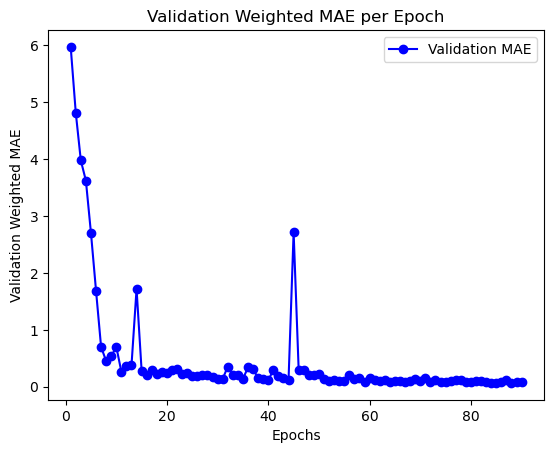

In [17]:
val_weighted_mae_per_epoch = history.history.get('val_loss', [])

print(sorted(val_weighted_mae_per_epoch)[0], sorted(val_weighted_mae_per_epoch)[1])

epochs = range(1, len(val_weighted_mae_per_epoch) + 1)  # X-axis representing epochs

# Create a line plot
plt.plot(epochs, val_weighted_mae_per_epoch, marker='o', linestyle='-', color='b', label='Validation MAE')

# Add labels and title
plt.xlabel('Epochs')
plt.ylabel('Validation Weighted MAE')
plt.title('Validation Weighted MAE per Epoch')

# Optionally, add a legend
plt.legend()

# Show the plot
plt.show()


## 4b. Overall Results

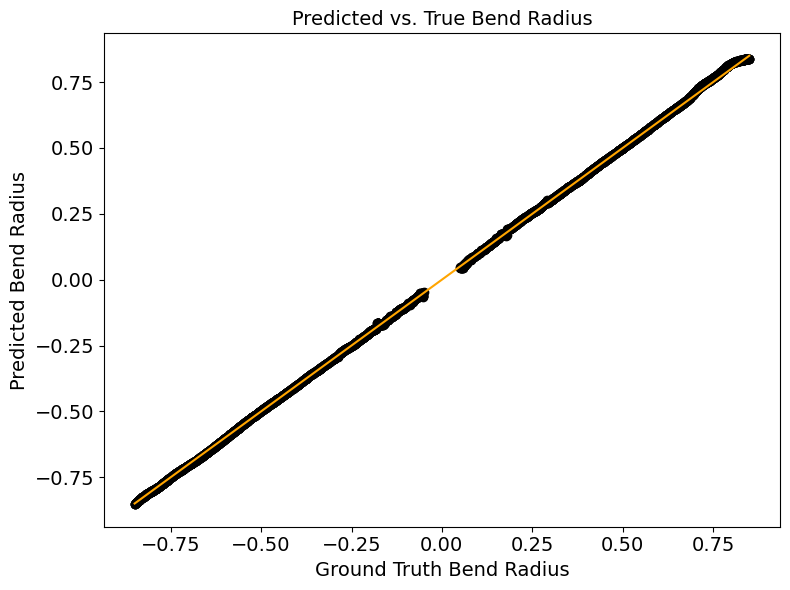

In [18]:
fig, ax = plt.subplots(figsize=(8, 6))  # One plot, adjusted size

ax.plot([min(y_test_f), max(y_test_f)], [min(y_test_f), max(y_test_f)], 'orange')
ax.scatter(y_test_f, y_pred, alpha=1, marker='o', color='black')
ax.set_xlabel("Ground Truth Bend Radius", fontsize=14)
ax.set_ylabel("Predicted Bend Radius", fontsize=14)
ax.set_title("Predicted vs. True Bend Radius", fontsize=14)

for ax in plt.gcf().get_axes():
    ax.tick_params(axis='both', labelsize=14)

plt.tight_layout()
plt.show()


In [19]:
y_pred = np.array(y_pred)  # Replace with your actual predicted values
y_test_f = np.array(y_test_f)  # Replace with your actual ground truth values

y_pred = y_pred.flatten()
y_test_f = y_test_f.flatten()

# 1. For Positive Values Only:
positive_mask = (y_pred > 0) & (y_test_f > 0)  # Mask for positive values in both y_pred and y_test_f
y_pred_positive = y_pred[positive_mask]  # Filter positive predictions
y_test_f_positive = y_test_f[positive_mask]  # Filter positive ground truths

# Calculate MAE for positive values only
positive_absolute_errors = np.abs(y_pred_positive - y_test_f_positive)
positive_mae = np.mean(positive_absolute_errors)

# 2. For Negative Values Only:
negative_mask = (y_pred < 0) & (y_test_f < 0)  # Mask for negative values in both y_pred and y_test_f
y_pred_negative = y_pred[negative_mask]  # Filter negative predictions
y_test_f_negative = y_test_f[negative_mask]  # Filter negative ground truths

# Calculate MAE for negative values only
negative_absolute_errors = np.abs(y_pred_negative - y_test_f_negative)
negative_mae = np.mean(negative_absolute_errors)

# Print results
print(f"MAE for Positive Bends: {positive_mae:.4f}")
print("Positive Bends % Error:", round((positive_mae)/statistics.mean(abs(y_test_f_positive))*100, 2), "%\n")

print(f"MAE for Negative Bends: {negative_mae:.4f}")
print("Negative Bends % Error:", round((negative_mae)/statistics.mean(abs(y_test_f_negative))*100, 2), "%")

MAE for Positive Bends: 0.0044
Positive Bends % Error: 0.99 %

MAE for Negative Bends: 0.0021
Negative Bends % Error: 0.48 %


0.014292464
0.020781219


(array([706., 451., 126.,  74., 102.,  27.,   2.,   4.,   4.,   4.]),
 array([5.72204590e-06, 1.43439625e-03, 2.86307046e-03, 4.29174444e-03,
        5.72041888e-03, 7.14909285e-03, 8.57776683e-03, 1.00064408e-02,
        1.14351157e-02, 1.28637897e-02, 1.42924637e-02]),
 <BarContainer object of 10 artists>)

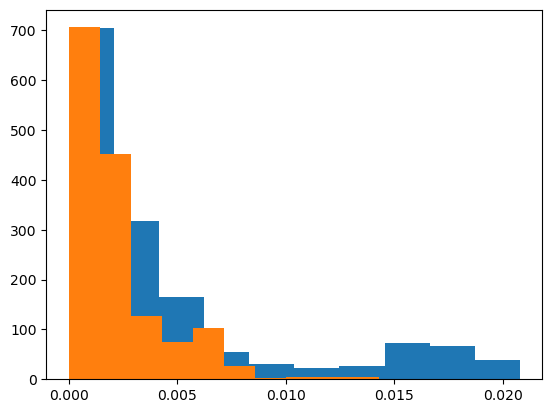

In [20]:
print(negative_absolute_errors.max())
print(positive_absolute_errors.max())
plt.hist(positive_absolute_errors)
plt.hist(negative_absolute_errors)


## 4d. Import Data and Model Weights

In [15]:
pos_tm_0084 = h5py.File('../data/26x26 TM Data/0.0840.mat','r') # pass the 26x26 TMs for the following bend radii
neg_tm_neg0084 = h5py.File('../data/26x26 TM Data/-0.0840.mat','r')
pos_tm_03261 = h5py.File('../data/26x26 TM Data/0.3261.mat','r')
neg_tm_neg03261 = h5py.File('../data/26x26 TM Data/-0.3261.mat','r')
pos_tm_07015 = h5py.File('../data/26x26 TM Data/0.7015.mat','r')
neg_tm_neg07015 = h5py.File('../data/26x26 TM Data/-0.7015.mat','r')

pos_tm_0084 = pos_tm_0084['trainData_in']
neg_tm_neg0084 = neg_tm_neg0084['trainData_in']
pos_tm_03261 = pos_tm_03261['trainData_in']
neg_tm_neg03261 = neg_tm_neg03261['trainData_in']
pos_tm_07015 = pos_tm_07015['trainData_in']
neg_tm_neg07015 = neg_tm_neg07015['trainData_in']

print("pos_tm_0084 shape:", pos_tm_0084.shape)
print("neg_tm_neg0084 shape:", neg_tm_neg0084.shape,"\n")
print("pos_tm_03261 shape:", pos_tm_03261.shape)
print("neg_tm_neg03261 shape:", neg_tm_neg03261.shape,"\n")
print("pos_tm_07015 shape:", pos_tm_07015.shape)
print("neg_tm_neg07015 shape:", neg_tm_neg07015.shape,"\n")

def prep_tm_radius_33(positive_tm, negative_tm, pos_radius, neg_radius):

    pos_tm_reshaped = np.transpose(positive_tm, (2, 0, 1)).reshape(1, 52, 52)
    neg_tm_reshaped = np.transpose(negative_tm, (2, 0, 1)).reshape(1, 52, 52)

    pos_radius_array = np.array(pos_radius)
    pos_radius_reshaped = pos_radius_array.flatten()
    neg_radius_array = np.array(neg_radius)
    neg_radius_reshaped = neg_radius_array.flatten()

    return pos_tm_reshaped, neg_tm_reshaped, pos_radius_reshaped, neg_radius_reshaped

pos_tm_reshaped_0084, neg_tm_reshaped_neg0084, pos_radius_0084, neg_radius_neg0084 = prep_tm_radius_33(pos_tm_0084, neg_tm_neg0084, 0.0840, -0.0840)
pos_tm_reshaped_03261, neg_tm_reshaped_neg03261, pos_radius_03261, neg_radius_neg03261 = prep_tm_radius_33(pos_tm_03261, neg_tm_neg03261, 0.3261, -0.3261)
pos_tm_reshaped_07015, neg_tm_reshaped_neg07015, pos_radius_07015, neg_radius_neg07015 = prep_tm_radius_33(pos_tm_07015, neg_tm_neg07015, 0.7015, -0.7015)


pos_tm_0084 shape: (52, 52, 1)
neg_tm_neg0084 shape: (52, 52, 1) 

pos_tm_03261 shape: (52, 52, 1)
neg_tm_neg03261 shape: (52, 52, 1) 

pos_tm_07015 shape: (52, 52, 1)
neg_tm_neg07015 shape: (52, 52, 1) 



In [ ]:
# Step 1: Build a new instance of the model architecture
model = SingleHeadResidualModel()

# Step 2: Load the trained weights
model.load_weights('../models/67%Model.weights.h5')

## 4c. +-0.084

In [19]:
t1 = time.perf_counter()
neg_loss_neg0084, neg_mae_neg0084 = model.evaluate(neg_tm_reshaped_neg0084, neg_radius_neg0084)
neg_y_pred_neg0084 = model.predict(neg_tm_reshaped_neg0084)
t2 = time.perf_counter()

print("\nActual radius:", neg_radius_neg0084[0])
print("Predicted radius:", round(neg_y_pred_neg0084[0][0], 5))
print("Percentage error", round(abs(neg_mae_neg0084/neg_radius_neg0084[0])*100, 3), "%")
print('\nTime taken to predict:', round(t2-t1, 3), 'seconds')

2025-07-21 14:52:52.078322: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - loss: 0.0532 - mae: 4.1783e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step

Actual radius: -0.084
Predicted radius: -0.08442
Percentage error 0.497 %

Time taken to predict: 1.382 seconds


The cells below need the full 78x78 TMs, which are not included. Their saved outputs show the results reported in the paper

In [20]:
neg_tm_neg0084_78 = h5py.File('../data/78x78 TM Data/Positive and Negative Bends/-0.0840.mat','r')
neg_tm_neg0084_78 = neg_tm_neg0084_78['trainData_in']
neg_tm_reshaped_neg0084_78 = np.transpose(neg_tm_neg0084_78, (2, 0, 1)).reshape(1, 156, 156)
neg_tm_neg008442 = h5py.File("../data/78x78 TM Data/Positive and Negative Bends/Comparison TMs for 26x26 Model/-0.08442.mat",'r')
neg_tm_neg008442 = neg_tm_neg008442['trainData_in']
neg_tm_reshaped_neg008442 = np.transpose(neg_tm_neg008442, (2, 0, 1)).reshape(1, 156, 156)

arr1_complex = to_complex(neg_tm_reshaped_neg0084_78[0].squeeze())  # Shape (78, 78)
arr2_complex = to_complex(neg_tm_reshaped_neg008442[0].squeeze())  # Shape (78, 78)

phaseError_TM = np.angle(np.trace(arr1_complex @ (arr2_complex.conj().T))) # same principle as above but compares the actual TM with the TM chosen by the TM error metric
error_TM = np.linalg.norm(arr2_complex - arr1_complex * np.exp(-1j*phaseError_TM))/np.linalg.norm(arr1_complex) * 100 # same principle as above

print(f"Difference between -0.0840 and -0.08442 TMs based on phase alignment : {error_TM:.2f}% ")


Difference between -0.0840 and -0.08442 TMs based on phase alignment : 5.30% 


Real TM (-0.084m), size: (78, 78)
Predicted TM (-0.08442m), size: (78, 78)
Error TM: 5.29720%


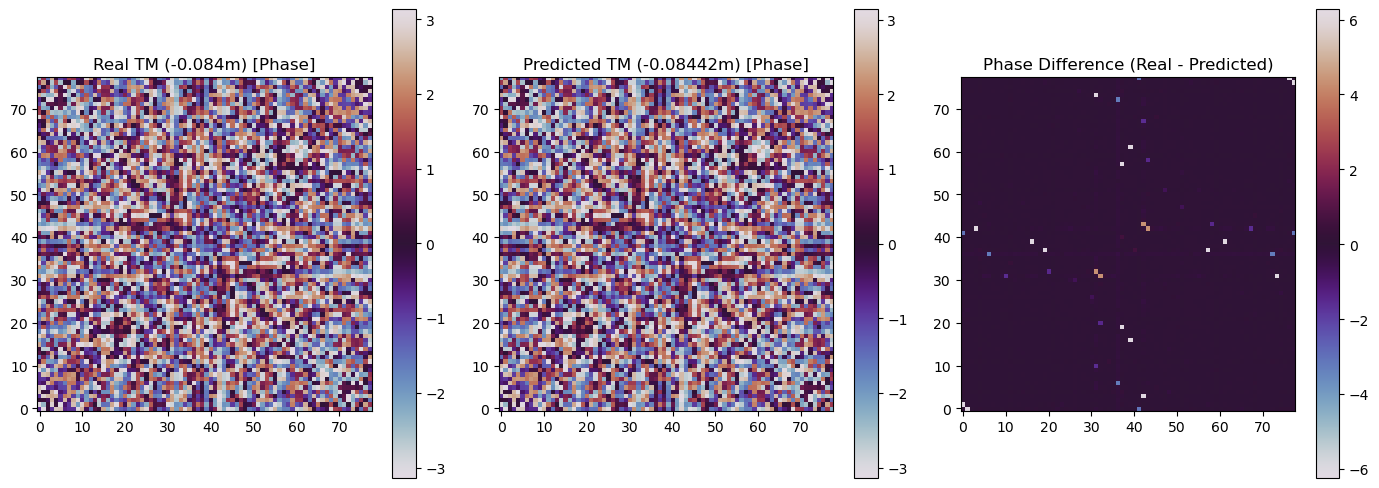

In [21]:
compare_real_and_pred_tms(arr1_complex, arr2_complex, -0.0840, -0.08442, 'imag')

In [22]:
t1 = time.perf_counter()
pos_loss_0084, pos_mae_0084 = model.evaluate(pos_tm_reshaped_0084, pos_radius_0084)
pos_y_pred_0084 = model.predict(pos_tm_reshaped_0084)
t2 = time.perf_counter()

print("\nActual radius:", pos_radius_0084[0])
print("Predicted radius:", round(pos_y_pred_0084[0][0], 5))
print("Percentage error", round(abs(pos_mae_0084/pos_radius_0084[0])*100, 3), "%")
print('\nTime taken to predict:', round(t2-t1, 3), 'seconds')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 0.0771 - mae: 5.6634e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

Actual radius: 0.084
Predicted radius: 0.08457
Percentage error 0.674 %

Time taken to predict: 0.095 seconds


In [23]:
pos_tm_0084_78 = h5py.File('../data/78x78 TM Data/Positive and Negative Bends/0.0840.mat','r')
pos_tm_0084_78 = pos_tm_0084_78['trainData_in']
pos_tm_reshaped_0084_78 = np.transpose(pos_tm_0084_78, (2, 0, 1)).reshape(1, 156, 156)
pos_tm_008457 = h5py.File("../data/78x78 TM Data/Positive and Negative Bends/Comparison TMs for 26x26 Model/0.08457.mat",'r')
pos_tm_008457 = pos_tm_008457['trainData_in']
pos_tm_reshaped_008457 = np.transpose(pos_tm_008457, (2, 0, 1)).reshape(1, 156, 156)

arr1_complex = to_complex(pos_tm_reshaped_0084_78[0].squeeze())  # Shape (78, 78)
arr2_complex = to_complex(pos_tm_reshaped_008457[0].squeeze())  # Shape (78, 78)

phaseError_TM = np.angle(np.trace(arr1_complex @ (arr2_complex.conj().T))) # same principle as above but compares the actual TM with the TM chosen by the TM error metric
error_TM = np.linalg.norm(arr2_complex - arr1_complex * np.exp(-1j*phaseError_TM))/np.linalg.norm(arr1_complex) * 100 # same principle as above

print(f"Difference between 0.0840 and 0.08457 TMs based on phase alignment : {error_TM:.2f}% ")


Difference between 0.0840 and 0.08457 TMs based on phase alignment : 7.15% 


## 4d. +-0.3261

In [24]:
t1 = time.perf_counter()
neg_loss_neg03261, neg_mae_neg03261 = model.evaluate(neg_tm_reshaped_neg03261, neg_radius_neg03261)
neg_y_pred_neg03261 = model.predict(neg_tm_reshaped_neg03261)
t2 = time.perf_counter()

print("\nActual radius:", neg_radius_neg03261[0])
print("Predicted radius:", round(neg_y_pred_neg03261[0][0], 5))
print("Percentage error", round(abs(neg_mae_neg03261/neg_radius_neg03261[0])*100, 3), "%")
print('\nTime taken to predict:', round(t2-t1, 3), 'seconds')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0024 - mae: 2.6584e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Actual radius: -0.3261
Predicted radius: -0.32637
Percentage error 0.082 %

Time taken to predict: 0.1 seconds


In [25]:
neg_tm_neg03261_78 = h5py.File('../data/78x78 TM Data/Positive and Negative Bends/-0.3261.mat','r')
neg_tm_neg03261_78 = neg_tm_neg03261_78['trainData_in']
neg_tm_reshaped_neg03261_78 = np.transpose(neg_tm_neg03261_78, (2, 0, 1)).reshape(1, 156, 156)
neg_tm_neg032637 = h5py.File("../data/78x78 TM Data/Positive and Negative Bends/Comparison TMs for 26x26 Model/-0.32637.mat",'r')
neg_tm_neg032637 = neg_tm_neg032637['trainData_in']
neg_tm_reshaped_neg032637 = np.transpose(neg_tm_neg032637, (2, 0, 1)).reshape(1, 156, 156)

arr1_complex = to_complex(neg_tm_reshaped_neg03261_78[0].squeeze())  # Shape (78, 78)
arr2_complex = to_complex(neg_tm_reshaped_neg032637[0].squeeze())  # Shape (78, 78)

phaseError_TM = np.angle(np.trace(arr1_complex @ (arr2_complex.conj().T)))
error_TM = np.linalg.norm(arr2_complex - arr1_complex * np.exp(-1j*phaseError_TM))/np.linalg.norm(arr1_complex) * 100

print(f"Difference between -0.3261 and -0.32637 TMs based on phase alignment : {error_TM:.5f}% ")


Difference between -0.3261 and -0.32637 TMs based on phase alignment : 0.05899% 


Real TM (-0.3261m), size: (78, 78)
Predicted TM (-0.32637m), size: (78, 78)
Error TM: 0.05899%


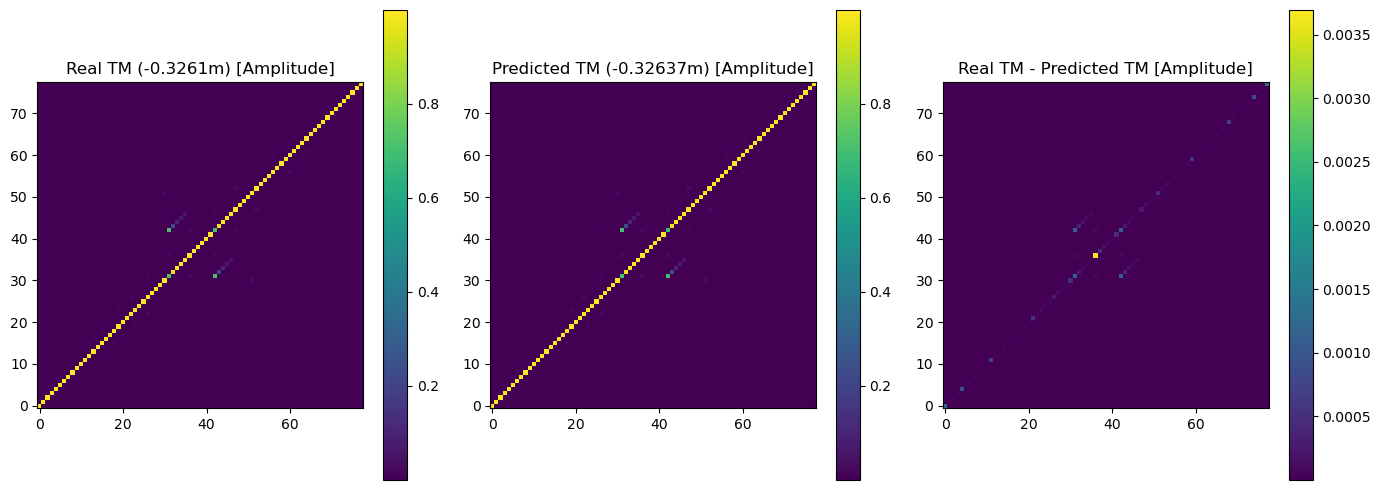

In [26]:
compare_real_and_pred_tms(arr1_complex, arr2_complex, -0.3261, -0.32637, 'real')

In [27]:
t1 = time.perf_counter()
pos_loss_03261, pos_mae_03261 = model.evaluate(pos_tm_reshaped_03261, pos_radius_03261)
pos_y_pred_03261 = model.predict(pos_tm_reshaped_03261)
t2 = time.perf_counter()

print("\nActual radius:", pos_radius_03261[0])
print("Predicted radius:", round(pos_y_pred_03261[0][0], 5))
print("Percentage error", round(abs(pos_mae_03261/pos_radius_03261[0])*100, 3), "%")
print('\nTime taken to predict:', round(t2-t1, 3), 'seconds')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 0.0061 - mae: 6.5941e-04
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Actual radius: 0.3261
Predicted radius: 0.32676
Percentage error 0.202 %

Time taken to predict: 0.1 seconds


In [28]:
pos_tm_03261_78 = h5py.File('../data/78x78 TM Data/Positive and Negative Bends/0.3261.mat','r')
pos_tm_03261_78 = pos_tm_03261_78['trainData_in']
pos_tm_reshaped_03261_78 = np.transpose(pos_tm_03261_78, (2, 0, 1)).reshape(1, 156, 156)
pos_tm_032676 = h5py.File("../data/78x78 TM Data/Positive and Negative Bends/Comparison TMs for 26x26 Model/0.32676.mat",'r')
pos_tm_032676 = pos_tm_032676['trainData_in']
pos_tm_reshaped_032676 = np.transpose(pos_tm_032676, (2, 0, 1)).reshape(1, 156, 156)

arr1_complex = to_complex(pos_tm_reshaped_03261_78[0].squeeze())  # Shape (78, 78)
arr2_complex = to_complex(pos_tm_reshaped_032676[0].squeeze())  # Shape (78, 78)

phaseError_TM = np.angle(np.trace(arr1_complex @ (arr2_complex.conj().T))) # same principle as above but compares the actual TM with the TM chosen by the TM error metric
error_TM = np.linalg.norm(arr2_complex - arr1_complex * np.exp(-1j*phaseError_TM))/np.linalg.norm(arr1_complex) * 100 # same principle as above

print(f"Difference between 0.3261 and 0.32676 TMs based on phase alignment : {error_TM:.2f}% ")


Difference between 0.3261 and 0.32676 TMs based on phase alignment : 0.14% 


## 4e. +-0.7015

In [29]:
t1 = time.perf_counter()
neg_loss_neg07015, neg_mae_neg07015 = model.evaluate(neg_tm_reshaped_neg07015, neg_radius_neg07015)
neg_y_pred_neg07015 = model.predict(neg_tm_reshaped_neg07015)
t2 = time.perf_counter()

print("\nActual radius:", neg_radius_neg07015[0])
print("Predicted radius:", round(neg_y_pred_neg07015[0][0], 5))
print("Percentage error", round(abs(neg_mae_neg07015/neg_radius_neg07015[0])*100, 3), "%")
print('\nTime taken to predict:', round(t2-t1, 3), 'seconds')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - loss: 0.0094 - mae: 0.0046
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

Actual radius: -0.7015
Predicted radius: -0.70614
Percentage error 0.661 %

Time taken to predict: 0.096 seconds


In [30]:
neg_tm_neg07015_78 = h5py.File('../data/78x78 TM Data/Positive and Negative Bends/-0.7015.mat','r')
neg_tm_neg07015_78 = neg_tm_neg07015_78['trainData_in']
neg_tm_reshaped_neg07015_78 = np.transpose(neg_tm_neg07015_78, (2, 0, 1)).reshape(1, 156, 156)
neg_tm_neg070614 = h5py.File("../data/78x78 TM Data/Positive and Negative Bends/Comparison TMs for 26x26 Model/-0.70614.mat",'r')
neg_tm_neg070614 = neg_tm_neg070614['trainData_in']
neg_tm_reshaped_neg070614 = np.transpose(neg_tm_neg070614, (2, 0, 1)).reshape(1, 156, 156)

arr1_complex = to_complex(neg_tm_reshaped_neg07015_78[0].squeeze())  # Shape (78, 78)
arr2_complex = to_complex(neg_tm_reshaped_neg070614[0].squeeze())  # Shape (78, 78)

phaseError_TM = np.angle(np.trace(arr1_complex @ (arr2_complex.conj().T))) # same principle as above but compares the actual TM with the TM chosen by the TM error metric
error_TM = np.linalg.norm(arr2_complex - arr1_complex * np.exp(-1j*phaseError_TM))/np.linalg.norm(arr1_complex) * 100 # same principle as above

print(f"Difference between -0.7015 and -0.70614 TMs based on phase alignment : {error_TM:.2f}% ")


Difference between -0.7015 and -0.70614 TMs based on phase alignment : 0.10% 


In [31]:
t1 = time.perf_counter()
pos_loss_07015, pos_mae_07015 = model.evaluate(pos_tm_reshaped_07015, pos_radius_07015)
pos_y_pred_07015 = model.predict(pos_tm_reshaped_07015)
t2 = time.perf_counter()

print("\nActual radius:", pos_radius_07015[0])
print("Predicted radius:", round(pos_y_pred_07015[0][0], 5))
print("Percentage error", round(abs(pos_mae_07015/pos_radius_07015[0])*100, 3), "%")
print('\nTime taken to predict:', round(t2-t1, 3), 'seconds')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 0.0269 - mae: 0.0131
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step

Actual radius: 0.7015
Predicted radius: 0.71457
Percentage error 1.863 %

Time taken to predict: 0.096 seconds


In [32]:
pos_tm_07015_78 = h5py.File('../data/78x78 TM Data/Positive and Negative Bends/0.7015.mat','r')
pos_tm_07015_78 = pos_tm_07015_78['trainData_in']
pos_tm_reshaped_07015_78 = np.transpose(pos_tm_07015_78, (2, 0, 1)).reshape(1, 156, 156)
pos_tm_071457 = h5py.File("../data/78x78 TM Data/Positive and Negative Bends/Comparison TMs for 26x26 Model/0.71457.mat",'r')
pos_tm_071457 = pos_tm_071457['trainData_in']
pos_tm_reshaped_071457 = np.transpose(pos_tm_071457, (2, 0, 1)).reshape(1, 156, 156)

arr1_complex = to_complex(pos_tm_reshaped_07015_78[0].squeeze())  # Shape (78, 78)
arr2_complex = to_complex(pos_tm_reshaped_071457[0].squeeze())  # Shape (78, 78)

phaseError_TM = np.angle(np.trace(arr1_complex @ (arr2_complex.conj().T))) # same principle as above but compares the actual TM with the TM chosen by the TM error metric
error_TM = np.linalg.norm(arr2_complex - arr1_complex * np.exp(-1j*phaseError_TM))/np.linalg.norm(arr1_complex) * 100 # same principle as above

print(f"Difference between 0.7015 and 0.71457 TMs based on phase alignment : {error_TM:.2f}% ")


Difference between 0.7015 and 0.71457 TMs based on phase alignment : 0.28% 


## 4f. TM Error Performance

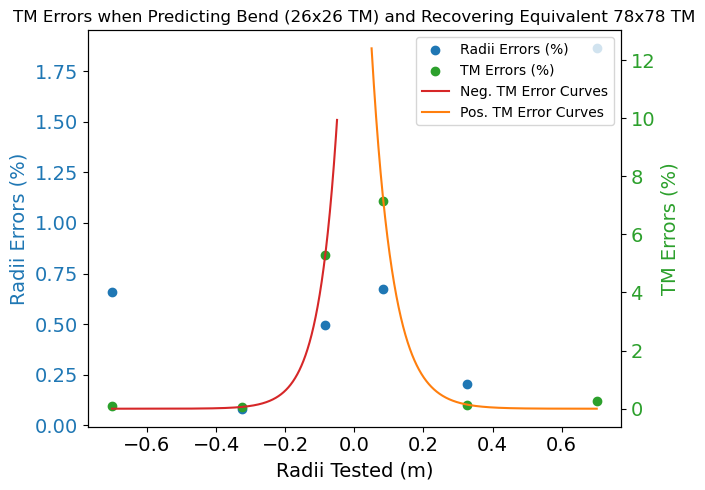

TM Errors Fit Parameters (x < -0.05): TM Error = 25.05 * exp(-18.49 * |x|)
TM Errors Fit Parameters (x > 0.05):  TM Error = 27.88 * exp(-16.20 * |x|)


In [33]:
radii_tested = [-0.7015, -0.3261, -0.084, 0.084, 0.3261, 0.7015]
radii_errors = [0.661, 0.082, 0.497, 0.674, 0.202, 1.863]
TM_errors = [0.1, 0.06, 5.30, 7.15, 0.14, 0.28]

# Define the exponential model: y = a * exp(b * x)
def exponential_model(x, a, b):
    return a * np.exp(b * x)

# Separate the data into two parts based on the sign of radii_tested
radii_tested_neg = [r for r in radii_tested if r < 0]
TM_errors_neg = [TM_errors[i] for i in range(len(radii_tested)) if radii_tested[i] < 0]

radii_tested_pos = [r for r in radii_tested if r > 0]
TM_errors_pos = [TM_errors[i] for i in range(len(radii_tested)) if radii_tested[i] > 0]

# Fit the model to the negative data (radii_tested < 0)
params_neg, _ = curve_fit(exponential_model, np.abs(radii_tested_neg), TM_errors_neg)
a_neg, b_neg = params_neg

# Fit the model to the positive data (radii_tested > 0)
params_pos, _ = curve_fit(exponential_model, np.abs(radii_tested_pos), TM_errors_pos)
a_pos, b_pos = params_pos

# Create a smooth line for the exponential fit of TM_errors (negative x and positive x)
x_vals_neg = np.linspace(min(radii_tested_neg), -0.05, 1000)
y_vals_neg = exponential_model(np.abs(x_vals_neg), a_neg, b_neg)

x_vals_pos = np.linspace(0.05, max(radii_tested_pos), 1000)
y_vals_pos = exponential_model(np.abs(x_vals_pos), a_pos, b_pos)

# Create the plot
fig, ax1 = plt.subplots(figsize=(7, 5))

# Plot data points for radii_errors on the left y-axis
ax1.scatter(radii_tested, radii_errors, color='tab:blue', label='Radii Errors (%)', zorder=5)
ax1.set_xlabel('Radii Tested (m)', fontsize=14)
ax1.set_ylabel('Radii Errors (%)', color='tab:blue', fontsize=14)
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Create a second y-axis for TM_errors
ax2 = ax1.twinx()

# Plot data points for TM_errors on the right y-axis
ax2.scatter(radii_tested, TM_errors, color='tab:green', label='TM Errors (%)', zorder=5)

# Plot the exponential fit for negative values
ax2.plot(x_vals_neg, y_vals_neg, color='tab:red', label=f'Neg. TM Error Curves', zorder=10, alpha = 1)

# Plot the exponential fit for positive values
ax2.plot(x_vals_pos, y_vals_pos, color='tab:orange', label=f'Pos. TM Error Curves', zorder=10, alpha = 1)

# Set labels for the right y-axis
ax2.set_ylabel('TM Errors (%)', color='tab:green', fontsize=14)
ax2.tick_params(axis='y', labelcolor='tab:green')

# Combine the legends from both axes
fig.legend(loc='upper right', bbox_to_anchor=(1, 1), bbox_transform=ax1.transAxes)

for ax in plt.gcf().get_axes():
    ax.tick_params(axis='both', labelsize=14)

# Display the plot
plt.title("TM Errors when Predicting Bend (26x26 TM) and Recovering Equivalent 78x78 TM")
plt.tight_layout()
plt.show()

# Print the parameters of the fits for TM_errors
print(f"TM Errors Fit Parameters (x < -0.05): TM Error = {a_neg:.2f} * exp({b_neg:.2f} * |x|)")
print(f"TM Errors Fit Parameters (x > 0.05):  TM Error = {a_pos:.2f} * exp({b_pos:.2f} * |x|)")


In [34]:
def predicted_tm_error(radius):

    if radius > -0.05 and radius < 0.05:
        print(f'Radius not allowed')
    else:
        if radius < 0.05:
            print(f'Predicted TM Error for radius {radius}m: {round(25.05 * np.exp(-18.49 * abs(radius)), 2)}%')
        else:
            print(f'Predicted TM Error for radius {radius}m: {round(27.88 * np.exp(-16.20 * abs(radius)), 2)}%')

predicted_tm_error(-0.05)
predicted_tm_error(0.05)

Predicted TM Error for radius -0.05m: 9.94%
Predicted TM Error for radius 0.05m: 12.4%


In [35]:
import math

def radius_for_given_tm_error(tm_error):

    neg = round((math.log(tm_error/25.05)/-18.49), 3)
    pos = round((math.log(tm_error/27.88)/-16.2), 3)

    if neg > pos:
        radius = neg
    else:
        radius = pos

    print(f'All radii larger than {radius}m have a maximum TM error of {tm_error}%')
    return

radius_for_given_tm_error(5)

All radii larger than 0.106m have a maximum TM error of 5%


## 4g. Tune Loss Function Constants

In [10]:
# single head with residual connections
class SingleHeadSelfAttentionResidual(layers.Layer):
    def __init__(self, embed_dim):
        super(SingleHeadSelfAttentionResidual, self).__init__()
        self.embed_dim = embed_dim

        # define dense layers for query, key, value transformations
        self.query_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())
        self.key_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                      bias_initializer=initializers.Zeros())
        self.value_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())
        self.output_dense = layers.Dense(embed_dim, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                         bias_initializer=initializers.Zeros())

        # normalization for stabilization. attention -> add residual connections -> normalisation is standard in transformers
        self.layer_norm = layers.LayerNormalization(epsilon=1e-6, beta_initializer='zeros', gamma_initializer='ones')

    def call(self, inputs):
        # inputs shape: (batch_size, num_patches, patch_height, embed_dim), (batch_size, 78, 2, 16)

        # compute queries, keys, and values
        queries = self.query_dense(inputs)  # shape: (None, 78, 2, 16)
        keys = self.key_dense(inputs)       # shape: (None, 78, 2, 16)
        values = self.value_dense(inputs)   # shape: (None, 78, 2, 16)

        # compute attention scores
        score = tf.matmul(queries, keys, transpose_b=True)  # shape: (batch_size, 78, 78)
        dim_k = tf.cast(tf.shape(keys)[-1], tf.float32) # cast the last dimension of keys (it's size) to a 32 bit floating-point number
        scaled_score = score / tf.math.sqrt(dim_k)  # scaling adds stability
        attention_weights = tf.nn.softmax(scaled_score, axis=-1)  # shape: (batch_size, 78, 78)

        # compute context vector as weighted sum of values
        context_vector = tf.matmul(attention_weights, values)  # shape: (batch_size, 78, 2, 16)

        # add residual connection (input + context vector)
        output_with_residual = layers.Add()([inputs, context_vector])

        # layer Normalization, mainly to ensure stability
        normalized_output = self.layer_norm(output_with_residual)

        # passing through dense layer to refine output, however i'm not sure how relevant this is
        return self.output_dense(normalized_output), attention_weights

#def weighted_mae_tunable(x_pos=0.004, x_neg=0.01):
#    def loss(y_true, y_pred):
#        weight_pos = tf.where(y_true > 0, 1.0 / (K.abs(y_true) + x_pos), 1.0 / (K.abs(y_true) + x_neg))
#        weight_neg = tf.where(y_true < 0, 1.0 / (K.abs(y_true) + x_neg))
#        balance = abs(weight_pos - weight_neg)
#        return K.mean(weight * K.abs(y_true - y_pred)/ K.abs(y_true)) * balance
#    return loss

def weighted_mae_tunable(x_pos=0.004, x_neg=0.01):
    def loss(y_true, y_pred):
        x_pos = 0.004
        x_neg = 0.01
        abs_error = K.abs(y_true - y_pred)

        # Compute weights
        weight = tf.where(y_true > 0, 1.0 / (K.abs(y_true) + x_pos), 1.0 / (K.abs(y_true) + x_neg))

        # Compute separate MAEs
        mae_pos = K.sum(weight * abs_error * tf.cast(y_true > 0, tf.float32)) / (K.sum(tf.cast(y_true > 0, tf.float32)) + K.epsilon())
        mae_neg = K.sum(weight * abs_error * tf.cast(y_true < 0, tf.float32)) / (K.sum(tf.cast(y_true < 0, tf.float32)) + K.epsilon())

        # Balance penalty (forces equal optimization)
        balance_penalty = 1.0 + K.abs(mae_pos - mae_neg)

        return K.mean(weight * K.abs(y_true - y_pred)/K.abs(y_true)) * balance_penalty
    return loss

def SingleHeadResidualModel_loss_func_tune(x_pos, x_neg, dense_neurons = int(22.212316006880545), learning_rate = round(0.005565249919690282, 6)):
    inputs = layers.Input(shape=(52, 52, 1))  # input shape: (batch_size, 156, 156, 1)

    patch_height, patch_width = 2, 52 # patch size: 2 rows and 156 columns
    num_patches = 52 // patch_height  # number of patches along the height dimension (i.e. 78)

    x = layers.Reshape((num_patches, patch_height, patch_width))(inputs)  # reshape input into 78 patches of size (2, 156)

    # z=x⋅W+b (x = input, W = learned weights (shape 156, 16), b = bias (vector of shape 16,), params = 2512 = 156 * 16 + 16
    # afterwards the output (z) is passed to the non-linear activation, where z = z if z >= 0, and z = a*z if z < 0. a is the slope for negative values, typically a small constant like 0.01.
    x = layers.Dense(dense_neurons, activation= tanh, kernel_initializer=initializers.GlorotUniform(seed=seed), # kernel initialiser = weights initialiser
                                            bias_initializer=initializers.Zeros())(x) # reduce feature dimension from 156 to 16 for each patch

    x = layers.LayerNormalization(epsilon=1e-6)(x) # provides stability and improves generalisation, it normalises the outputs of the previous layer using: (input - mean) / sqrt(var)

    x, _ = SingleHeadSelfAttentionResidual(embed_dim = dense_neurons)(x) # self-attention layer

    # reshape to 3D for global average pooling: (batch_size, num_patches, patch_height * embed_dim)
    # global average pooling 1D only accepts 3d tensors.
    x_reshaped = layers.Reshape((num_patches, patch_height * dense_neurons))(x)

    # originally had a flattening layer but replaced with global average pooling to help the model generalize better and reduce overfitting
    # pooling used to reduce spatial dimensions, in turn preventing overfitting.
    x_before_dense = layers.GlobalAveragePooling1D()(x_reshaped) # apply Global Average Pooling along the patches dimension only

    x = layers.LayerNormalization(epsilon=1e-6)(x_before_dense)

    # maybe i should've added an activation function (i.e. leaky_relu)
    output = layers.Dense(1, kernel_initializer=initializers.GlorotUniform(seed=seed),
                                        bias_initializer=initializers.Zeros())(x)

    # compile the model
    model = models.Model(inputs=inputs, outputs=output)
    model.compile(optimizer=Adam(learning_rate=learning_rate), loss=weighted_mae_tunable(x_pos, x_neg), metrics=['mae'])

    return model


In [ ]:
def tune_loss_function(x_pos, x_neg):
    fixed_batch_size = int(round(27.883189469819506, 0))
    fixed_epochs = int(round(56.345735791242774 + 24, 0))
    model = SingleHeadResidualModel_loss_func_tune(x_pos, x_neg)

    early_stopping = EarlyStopping(monitor='val_mae', mode='min', patience=30, restore_best_weights=True, verbose=0)

    model.fit(x_train_f, y_train_f, validation_data=(x_val_f, y_val_f),
              callbacks=[early_stopping], batch_size=fixed_batch_size, epochs=fixed_epochs, verbose=0)

    y_pred = model.predict(x_val_f)
    weighted_mae_value = K.eval(weighted_mae_tunable(x_pos, x_neg)(y_val_f, y_pred))

    return -weighted_mae_value  # Minimize the loss

# Define the parameter search space
pbounds = {
    'x_pos': (0.001, 0.01),
    'x_neg': (0.002, 0.15)
}

# Set up Bayesian Optimization
optimizer = BayesianOptimization(
    f=tune_loss_function,  # Objective function
    pbounds=pbounds,
    random_state=42
)

# Run the optimization
optimizer.maximize(init_points=10, n_iter=15)  # Adjust iterations as needed

# Best parameters found
best_params = optimizer.max['params']
print(f"Best alpha pos: {best_params['x_pos']}, best alpha neg: {best_params['x_neg']}")
